# LAB 3 — Điều kiện ảnh và tiền xử lý

**Mục tiêu:** kiểm tra ảnh hưởng của nhiễu, độ tương phản thấp và mật độ chi tiết đến kết quả Canny; so sánh trước/sau tiền xử lý và rút ra kết luận.


## 1. Khởi tạo và cấu hình

- Ảnh được đọc ở thang xám trước khi chạy Canny.
- Ngưỡng Canny cố định: `threshold1 = 80`, `threshold2 = 160`, `L2gradient = True`.


In [ ]:
from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

CWD = Path.cwd().resolve()
ROOT = CWD.parent if CWD.name.lower() == "notebook" else CWD

FIG_DIR = ROOT / "result" / "figures" / "tv3_conditions"
TABLE_DIR = ROOT / "result" / "tables"
FALLBACK_DIR = ROOT / "data" / "tv3_fallback_samples"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

CANNY_LOW = 80
CANNY_HIGH = 160
L2_GRADIENT = True
SEED = 42
NOISE_SIGMA = 25.0

print(f"Canny: threshold1={CANNY_LOW}, threshold2={CANNY_HIGH}, L2gradient={L2_GRADIENT}")

Repository root: D:\Computer-Vision-Group-2-main\Computer-Vision-Group-2\lab_2
Thư mục hình kết quả: D:\Computer-Vision-Group-2-main\Computer-Vision-Group-2\lab_2\result\figures\tv3_conditions
Canny: threshold1=80, threshold2=160, L2gradient=True


## 2. Đọc ảnh nguồn

Tên ảnh được tìm theo đúng các tên hiển thị trong thư mục ảnh của bạn. Nếu có nhiều bản sao, notebook chọn một bản ở repository (không lấy file trong thư mục kết quả).

In [37]:
from pathlib import Path
import cv2

EXCLUDED_DIRS = {
    ".git", ".venv", "venv", "__pycache__", ".ipynb_checkpoints",
    "result", "results", "build", "dist"
}

ROOT = Path.cwd()

for candidate in [ROOT, *ROOT.parents]:
    if (candidate / "data" / "input").is_dir():
        ROOT = candidate
        break

INPUT_DIR = ROOT / "data" / "input"


def load_gray(path):
    image = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)

    if image is None:
        raise FileNotFoundError(f"Không đọc được ảnh: {path}")

    if image.ndim != 2:
        raise ValueError(f"Ảnh không ở thang xám: {path}")

    return image

camera_path = INPUT_DIR / "04_anh_that_nhieu_chi_tiet.png"
coins_path = INPUT_DIR / "05_dong_xu_phan_doan.png"

if not camera_path.is_file():
    raise FileNotFoundError(f"Không tìm thấy ảnh {camera_path}")

if not coins_path.is_file():
    raise FileNotFoundError(f"Không tìm thấy ảnh {coins_path}")

# Đọc ảnh
camera_gray = load_gray(camera_path)
coins_gray = load_gray(coins_path)

# Hiển thị thông tin
print("Đã đọc ảnh camera:", camera_path)
print("Đã đọc ảnh đồng xu:", coins_path)
print("Kích thước ảnh camera:", camera_gray.shape)
print("Kích thước ảnh đồng xu:", coins_gray.shape)

Đã đọc ảnh camera: d:\Computer-Vision-Group-2-main\Computer-Vision-Group-2\lab_2\data\input\04_anh_that_nhieu_chi_tiet.png
Đã đọc ảnh đồng xu: d:\Computer-Vision-Group-2-main\Computer-Vision-Group-2\lab_2\data\input\05_dong_xu_phan_doan.png
Kích thước ảnh camera: (512, 512)
Kích thước ảnh đồng xu: (303, 384)


## 3. Tạo ba điều kiện ảnh và định nghĩa tiền xử lý

1. **Nhiều nhiễu:** cộng nhiễu Gaussian có độ lệch chuẩn `σ = 25` vào ảnh camera; tiền xử lý bằng Gaussian blur `5×5`, `σ = 1.2`.
2. **Tương phản thấp:** giảm tương phản với `alpha = 0.35`, `beta = 100`; tiền xử lý bằng CLAHE (`clipLimit = 2.0`, `tileGridSize = (8, 8)`) rồi Gaussian blur `3×3`, `σ = 0.6`.
3. **Nhiều chi tiết:** dùng ảnh đồng xu có nhiều hoa văn; tiền xử lý bằng Gaussian blur nhẹ `3×3`, `σ = 0.6` để hạn chế nhiễu nhỏ nhưng cố gắng giữ đường biên.

Các tham số được ghi lại trong phần hình và bảng kết quả. Cùng một cặp ngưỡng Canny được dùng trước và sau tiền xử lý.

In [38]:
# Ảnh nhiều nhiễu: sinh nhiễu có thể tái lập từ ảnh camera nguồn.
rng = np.random.default_rng(SEED)
noise = rng.normal(loc=0.0, scale=NOISE_SIGMA, size=camera_gray.shape)
noisy_image = np.clip(camera_gray.astype(np.float32) + noise, 0, 255).astype(np.uint8)

# Ảnh tương phản thấp: biến đổi tuyến tính từ cùng ảnh camera nguồn.
low_contrast_image = cv2.convertScaleAbs(camera_gray, alpha=0.35, beta=100)

# Ảnh nhiều chi tiết: giữ nguyên ảnh đồng xu làm đầu vào của điều kiện này.
detailed_image = coins_gray.copy()

clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))

cases = [
    {
        "key": "noisy",
        "name": "Ảnh nhiều nhiễu",
        "input": noisy_image,
        "preprocess": lambda img: cv2.GaussianBlur(img, (5, 5), sigmaX=1.2),
        "preprocess_name": "Gaussian blur 5×5, σ=1.2",
        "creation": f"Ảnh camera + nhiễu Gaussian (σ={NOISE_SIGMA}, seed={SEED})",
        "before_observation": "Thường xuất hiện nhiều biên ngắn/đứt đoạn do nhiễu; có thể có biên giả trong vùng vốn tương đối phẳng.",
        "after_observation": "Làm mờ nhẹ trước Canny thường giảm biên rời rạc do nhiễu và giúp đường bao chính rõ hơn; làm mờ quá mạnh có thể xóa chi tiết nhỏ.",
        "recommendation": "Nên thử blur khi nhiễu rõ; tăng kernel hoặc σ từ từ và kiểm tra chi tiết nhỏ có bị mất không.",
    },
    {
        "key": "low_contrast",
        "name": "Ảnh tương phản thấp",
        "input": low_contrast_image,
        "preprocess": lambda img: cv2.GaussianBlur(clahe.apply(img), (3, 3), sigmaX=0.6),
        "preprocess_name": "CLAHE (clipLimit=2.0, tileGridSize=8×8) + Gaussian blur 3×3, σ=0.6",
        "creation": "Từ ảnh camera: convertScaleAbs(alpha=0.35, beta=100)",
        "before_observation": "Độ chênh cường độ yếu có thể khiến một số biên thật không vượt ngưỡng Canny, nên biên có thể mờ hoặc không liên tục.",
        "after_observation": "CLAHE có thể làm rõ biên yếu; blur nhẹ giúp hạn chế một phần đáp ứng do nhiễu sau tăng tương phản. CLAHE cũng có nguy cơ khuếch đại kết cấu/nhiễu.",
        "recommendation": "Nên cân nhắc CLAHE/cân bằng histogram khi độ tương phản thấp; kiểm tra vùng phẳng để tránh tạo thêm biên giả.",
    },
    {
        "key": "high_detail",
        "name": "Ảnh nhiều chi tiết",
        "input": detailed_image,
        "preprocess": lambda img: cv2.GaussianBlur(img, (3, 3), sigmaX=0.6),
        "preprocess_name": "Gaussian blur nhẹ 3×3, σ=0.6",
        "creation": "Ảnh đồng xu có nhiều hoa văn và đường biên gần nhau; không thêm nhiễu nhân tạo",
        "before_observation": "Canny phát hiện nhiều biên, gồm đường bao hữu ích và chi tiết hoa văn nhỏ; các đường gần nhau có thể tạo bản đồ biên dày.",
        "after_observation": "Blur nhẹ thường giảm bớt cạnh li ti nhưng cũng có thể làm mất hoa văn nhỏ hoặc nhập các biên gần nhau.",
        "recommendation": "Chỉ dùng blur nhẹ nếu cần giảm rối; không tăng mức làm mờ khi mục tiêu là giữ kết cấu/hoa văn nhỏ.",
    },
]

for case in cases:
    case["processed"] = case["preprocess"](case["input"])
    case["edges_before"] = cv2.Canny(case["input"], CANNY_LOW, CANNY_HIGH, L2gradient=L2_GRADIENT)
    case["edges_after"] = cv2.Canny(case["processed"], CANNY_LOW, CANNY_HIGH, L2gradient=L2_GRADIENT)
    case["density_before"] = float(np.mean(case["edges_before"] > 0) * 100)
    case["density_after"] = float(np.mean(case["edges_after"] > 0) * 100)

print("Đã tạo 3 điều kiện ảnh và tính bản đồ biên trước/sau tiền xử lý.")

Đã tạo 3 điều kiện ảnh và tính bản đồ biên trước/sau tiền xử lý.


## 4. Hiển thị và lưu kết quả

Mỗi hình có bốn ô: **ảnh điều kiện đầu vào**, **biên Canny trước tiền xử lý**, **ảnh sau tiền xử lý**, và **biên Canny sau tiền xử lý**. Tỷ lệ pixel biên chỉ là thống kê mô tả để hỗ trợ quan sát, **không phải** Precision/Recall/F1 và không thể thay thế ground truth.

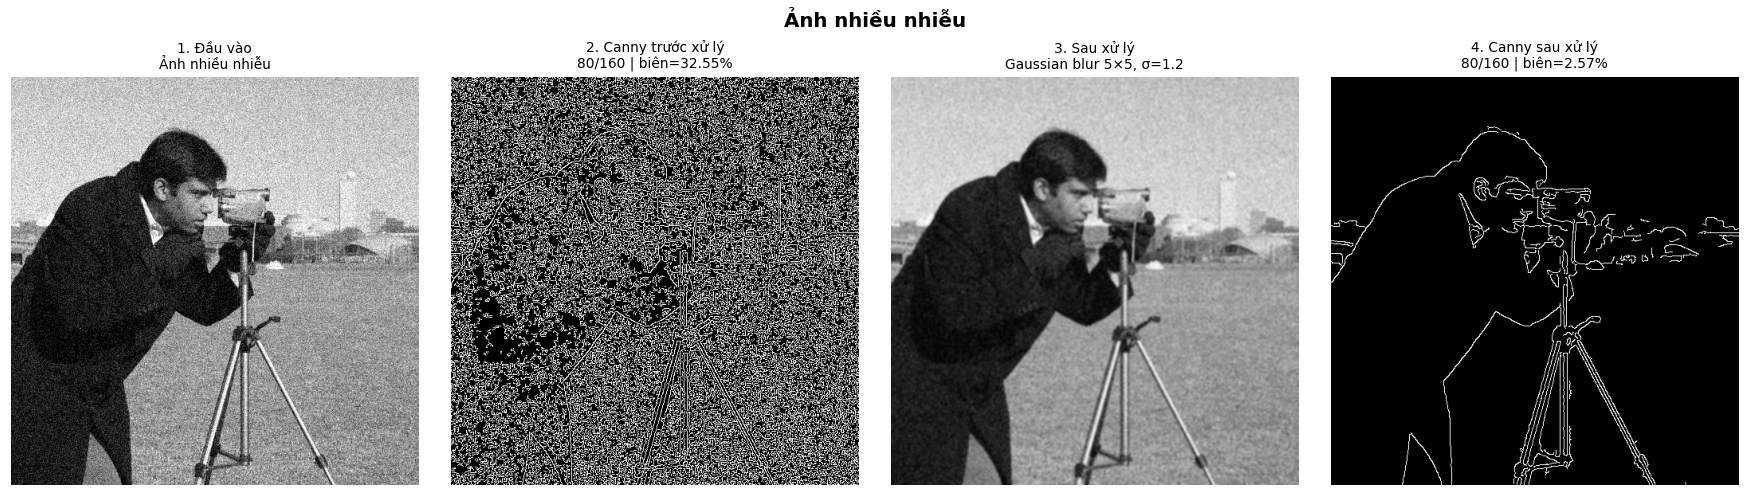

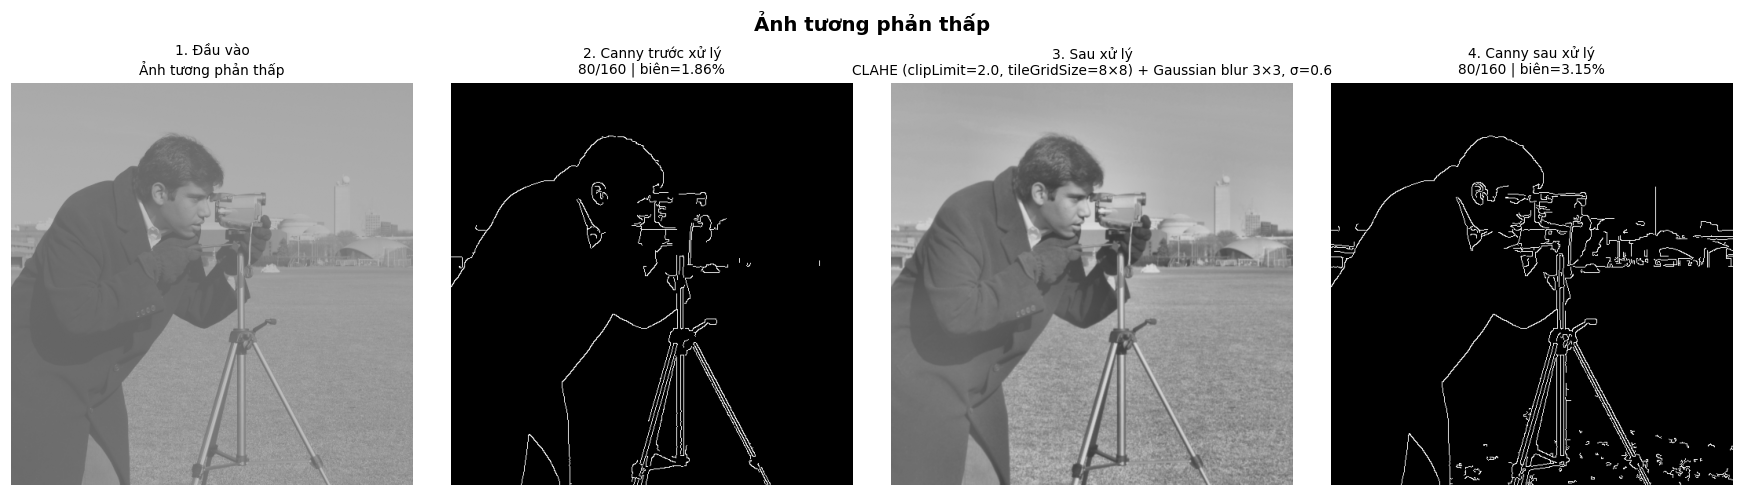

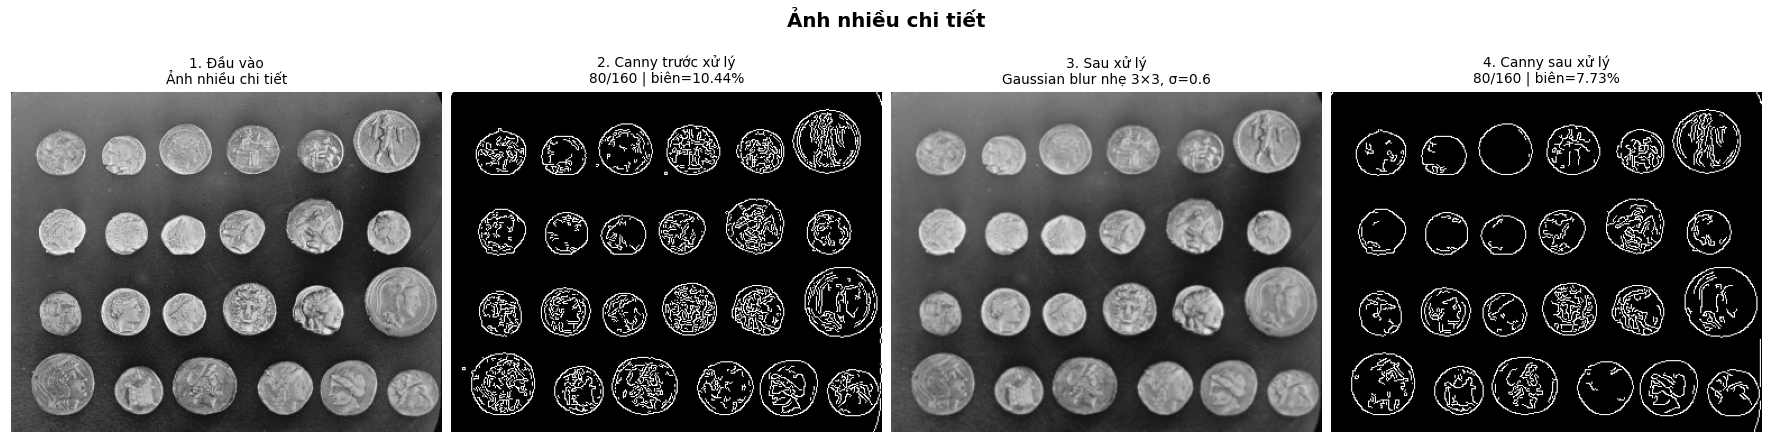

In [39]:
def save_case_figure(case):
    fig, axes = plt.subplots(1, 4, figsize=(16, 4.4), constrained_layout=True)
    panels = [
        (case["input"], f"1. Đầu vào\n{case['name']}", "gray"),
        (case["edges_before"], f"2. Canny trước xử lý\n{CANNY_LOW}/{CANNY_HIGH} | biên={case['density_before']:.2f}%", "gray"),
        (case["processed"], f"3. Sau xử lý\n{case['preprocess_name']}", "gray"),
        (case["edges_after"], f"4. Canny sau xử lý\n{CANNY_LOW}/{CANNY_HIGH} | biên={case['density_after']:.2f}%", "gray"),
    ]
    for ax, (image, title, cmap) in zip(axes, panels):
        ax.imshow(image, cmap=cmap, vmin=0, vmax=255)
        ax.set_title(title, fontsize=9)
        ax.axis("off")
    fig.suptitle(f"{case['name']}", fontsize=13, fontweight="bold")
    out_path = FIG_DIR / f"{ {'noisy':'01_canny_noisy_image','low_contrast':'02_canny_low_contrast','high_detail':'03_canny_high_detail'}[case['key']] }.png"
    fig.savefig(out_path, dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)

for case in cases:
    save_case_figure(case)

## 5. Bảng so sánh và quan sát định tính

Số lượng biên được tham chiếu qua tỷ lệ pixel biên, còn đánh giá biên giả, biên bị mất và tính liên tục dựa trên quan sát trực quan. Vì bộ dữ liệu không có bản đồ biên chuẩn (*ground truth*), notebook không tính Precision, Recall hay F1.

In [40]:
rows = []
for case in cases:
    rows.append({
        "Điều kiện ảnh": case["name"],
        "Cách tạo ảnh": case["creation"],
        "Tiền xử lý": case["preprocess_name"],
        "Pixel biên trước (%)": round(case["density_before"], 2),
        "Pixel biên sau (%)": round(case["density_after"], 2),
        "Quan sát trước xử lý": case["before_observation"],
        "Quan sát sau xử lý": case["after_observation"],
        "Khuyến nghị": case["recommendation"],
    })

summary_df = pd.DataFrame(rows)
display(summary_df)
csv_path = TABLE_DIR / "tv3_canny_conditions_summary.csv"
summary_df.to_csv(csv_path, index=False, encoding="utf-8-sig")

,Điều kiện ảnh,Cách tạo ảnh,Tiền xử lý,Pixel biên trước (%),Pixel biên sau (%),Quan sát trước xử lý,Quan sát sau xử lý,Khuyến nghị
0,Ảnh nhiều nhiễu,"Ảnh camera + nhiễu Gaussian (σ=25.0, seed=42)","Gaussian blur 5×5, σ=1.2",32.55,2.57,Thường xuất hiện nhiều biên ngắn/đứt đoạn do nhiễu; có t...,Làm mờ nhẹ trước Canny thường giảm biên rời rạc do nhiễu...,Nên thử blur khi nhiễu rõ; tăng kernel hoặc σ từ từ và k...
1,Ảnh tương phản thấp,"Từ ảnh camera: convertScaleAbs(alpha=0.35, beta=100)","CLAHE (clipLimit=2.0, tileGridSize=8×8) + Gaussian blur ...",1.86,3.15,Độ chênh cường độ yếu có thể khiến một số biên thật khôn...,CLAHE có thể làm rõ biên yếu; blur nhẹ giúp hạn chế một ...,Nên cân nhắc CLAHE/cân bằng histogram khi độ tương phản ...
2,Ảnh nhiều chi tiết,Ảnh đồng xu có nhiều hoa văn và đường biên gần nhau; khô...,"Gaussian blur nhẹ 3×3, σ=0.6",10.44,7.73,"Canny phát hiện nhiều biên, gồm đường bao hữu ích và chi...",Blur nhẹ thường giảm bớt cạnh li ti nhưng cũng có thể là...,Chỉ dùng blur nhẹ nếu cần giảm rối; không tăng mức làm m...


## 6. So sánh tổng quan tỷ lệ pixel biên


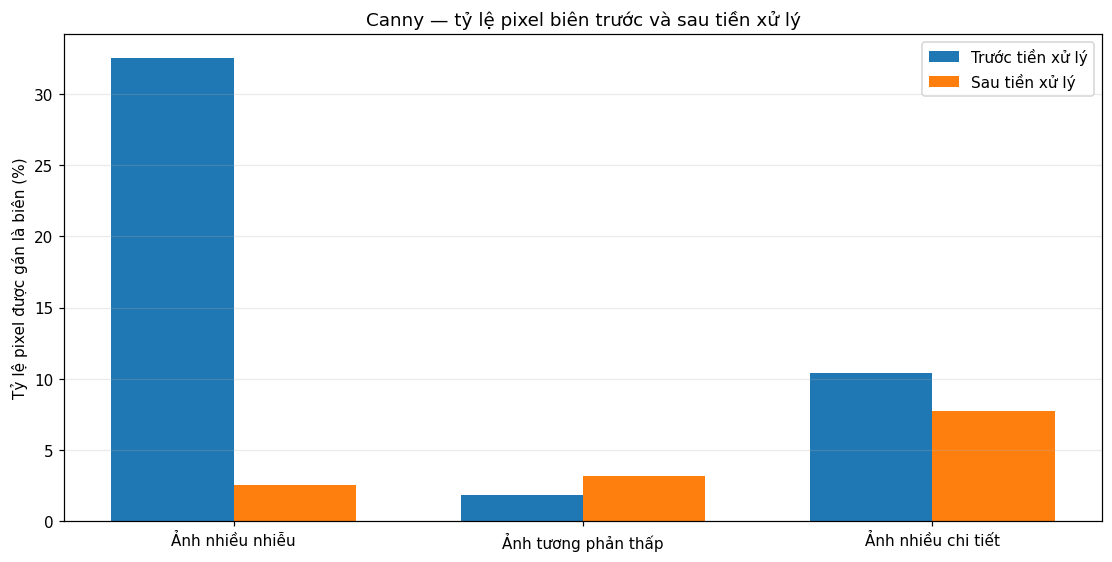

In [41]:
labels = [c["name"] for c in cases]
before = [c["density_before"] for c in cases]
after = [c["density_after"] for c in cases]
x = np.arange(len(labels))
width = 0.35
fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)
ax.bar(x - width/2, before, width, label="Trước tiền xử lý")
ax.bar(x + width/2, after, width, label="Sau tiền xử lý")
ax.set_ylabel("Tỷ lệ pixel được gán là biên (%)")
ax.set_title("Canny — tỷ lệ pixel biên trước và sau tiền xử lý")
ax.set_xticks(x, labels)
ax.legend()
ax.grid(axis="y", alpha=0.25)
overview_path = FIG_DIR / "04_edge_density_overview.png"
fig.savefig(overview_path, dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

## 7. Kết luận

**Ảnh nhiều nhiễu.** Nhiễu tạo ra dao động cường độ không thuộc đường bao vật thể, khiến Canny dễ sinh nhiều cạnh ngắn, rời rạc. Gaussian blur trước Canny thường hữu ích vì giảm biến thiên tần số cao. Tuy vậy, kernel hoặc σ quá lớn sẽ làm yếu đường biên thật và xóa chi tiết mảnh. Vì vậy, nên tiền xử lý khi nhiễu nhìn thấy rõ và tăng mức làm mờ từng bước.

**Ảnh tương phản thấp.** Khi cường độ hai phía của biên gần nhau, gradient có thể không đủ lớn để vượt ngưỡng Canny; một số đường biên có thể bị đứt hoặc bỏ sót. CLAHE có thể tăng khả năng nhìn thấy biên cục bộ. Tuy nhiên, CLAHE cũng có thể khuếch đại nhiễu và kết cấu nền, làm xuất hiện biên không mong muốn. Nên dùng khi ảnh thật sự thiếu tương phản và cần kiểm tra lại các vùng phẳng sau tăng tương phản.

**Ảnh nhiều chi tiết.** Canny vốn có thể tạo ra bản đồ biên dày khi ảnh chứa nhiều hoa văn hoặc đường biên gần nhau. Blur nhẹ có thể giảm bớt các cạnh vụn, nhưng đồng thời làm mất chi tiết nhỏ hoặc khiến các đường gần nhau nhập lại. Nếu mục tiêu là giữ hoa văn/chi tiết nhỏ, nên tránh tiền xử lý mạnh; có thể thử ảnh gốc hoặc blur rất nhẹ và lựa chọn dựa trên mục tiêu ứng dụng.

**Kết luận chung.** Không có một phép tiền xử lý tối ưu cho mọi ảnh. Nên chọn theo nguyên nhân làm giảm chất lượng: Gaussian blur cho nhiễu, CLAHE/cân bằng histogram cho tương phản thấp, và rất thận trọng với ảnh nhiều chi tiết. Luôn so sánh đầu vào, ảnh sau tiền xử lý và bản đồ biên trong cùng điều kiện ngưỡng; đánh giá biên thật, biên giả, biên bị mất và độ liên tục bằng quan sát nếu không có ground truth. Các tỷ lệ pixel biên trong bảng chỉ mô tả độ dày bản đồ biên, không phải thước đo độ chính xác.